In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Yo function le dataset load garera hamilai data return garcha.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2096s 12us/step


In [3]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


In [4]:
print("Data type:", X_train.dtype)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("Missing values:", np.isnan(X_train).sum())

print("Unique labels:", np.unique(y_train))

Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Missing values: 0
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [5]:
np.isnan(X_train).sum()
# 0

np.int64(0)

In [6]:
class_counts = np.bincount(y_train.flatten())

for class_id, count in enumerate(class_counts):
    print(f"Class {class_id}: {count} images")

Class 0: 5000 images
Class 1: 5000 images
Class 2: 5000 images
Class 3: 5000 images
Class 4: 5000 images
Class 5: 5000 images
Class 6: 5000 images
Class 7: 5000 images
Class 8: 5000 images
Class 9: 5000 images


In [7]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

for class_id, class_name in enumerate(class_names):
    print(f"{class_id}: {class_name}")

0: airplane
1: automobile
2: bird
3: cat
4: deer
5: dog
6: frog
7: horse
8: ship
9: truck


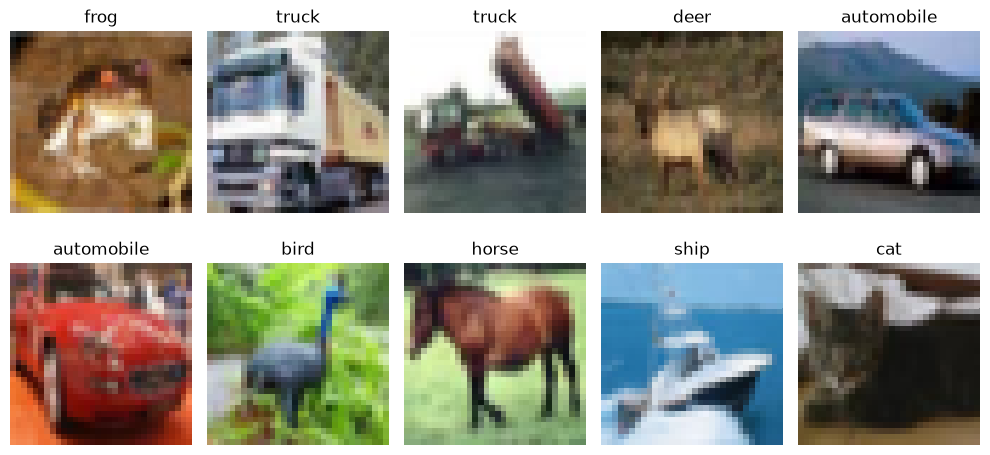

In [10]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
print("Image shape:", X_train[0].shape)
print("Pixel data type:", X_train[0].dtype)

Image shape: (32, 32, 3)
Pixel data type: uint8


In [12]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [13]:
print("Data type:", X_train.dtype)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Training image shape:", X_train.shape)

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training image shape: (50000, 32, 32, 3)


In [14]:
y_train.shape
# (50000, 1)

(50000, 1)

In [15]:
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (50000,)
Testing labels shape: (10000,)


In [16]:
X_train = X_train.reshape(50000, 3072)
X_test = X_test.reshape(10000, 3072)

print("Training images shape:", X_train.shape)
print("Testing images shape:", X_test.shape)

Training images shape: (50000, 3072)
Testing images shape: (10000, 3072)


In [17]:
print("Training labels shape:", y_train.shape)
print("First 10 labels:", y_train[:10])
print("First 10 class names:", [class_names[label] for label in y_train[:10]])

Training labels shape: (50000,)
First 10 labels: [6 9 9 4 1 1 2 7 8 3]
First 10 class names: ['frog', 'truck', 'truck', 'deer', 'automobile', 'automobile', 'bird', 'horse', 'ship', 'cat']


In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.3191 - loss: 1.9101 - val_accuracy: 0.3646 - val_loss: 1.8077
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 84s 37ms/step - accuracy: 0.3698 - loss: 1.7720 - val_accuracy: 0.3750 - val_loss: 1.7542
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 86s 37ms/step - accuracy: 0.3814 - loss: 1.7258 - val_accuracy: 0.3796 - val_loss: 1.7492
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 72s 29ms/step - accuracy: 0.3918 - loss: 1.7033 - val_accuracy: 0.3924 - val_loss: 1.7177
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 26ms/step - accuracy: 0.4003 - loss: 1.6826 - val_accuracy: 0.4098 - val_loss: 1.6723
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 49s 35ms/step - accuracy: 0.4040 - loss: 1.6725 - val_accuracy: 0.3908 - val_loss: 1.7242
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 64s 22ms/step - accuracy: 0.4102 - loss: 1.6600 - val_accuracy: 0.4118 - val_loss: 1.6793
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 70s 42ms/step - accuracy: 0.4120 -

In [21]:
print("Training accuracy:", history.history["accuracy"][-1])
print("Validation accuracy:", history.history["val_accuracy"][-1])

print("Training loss:", history.history["loss"][-1])
print("Validation loss:", history.history["val_loss"][-1])

Training accuracy: 0.4160444438457489
Validation accuracy: 0.4032000005245209
Training loss: 1.636530876159668
Validation loss: 1.6700359582901


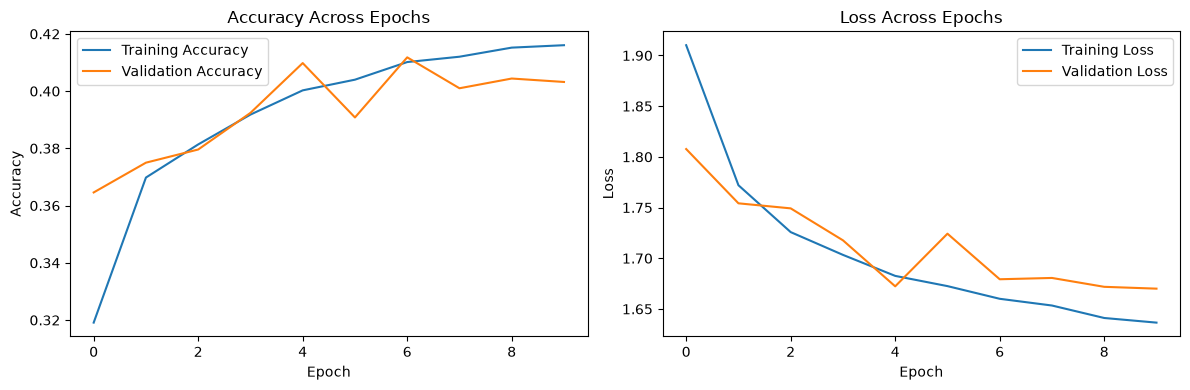

In [22]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4034 - loss: 1.6670
Test loss: 1.6670150756835938
Test accuracy: 0.4034000039100647
Test accuracy (%): 40.34000039100647


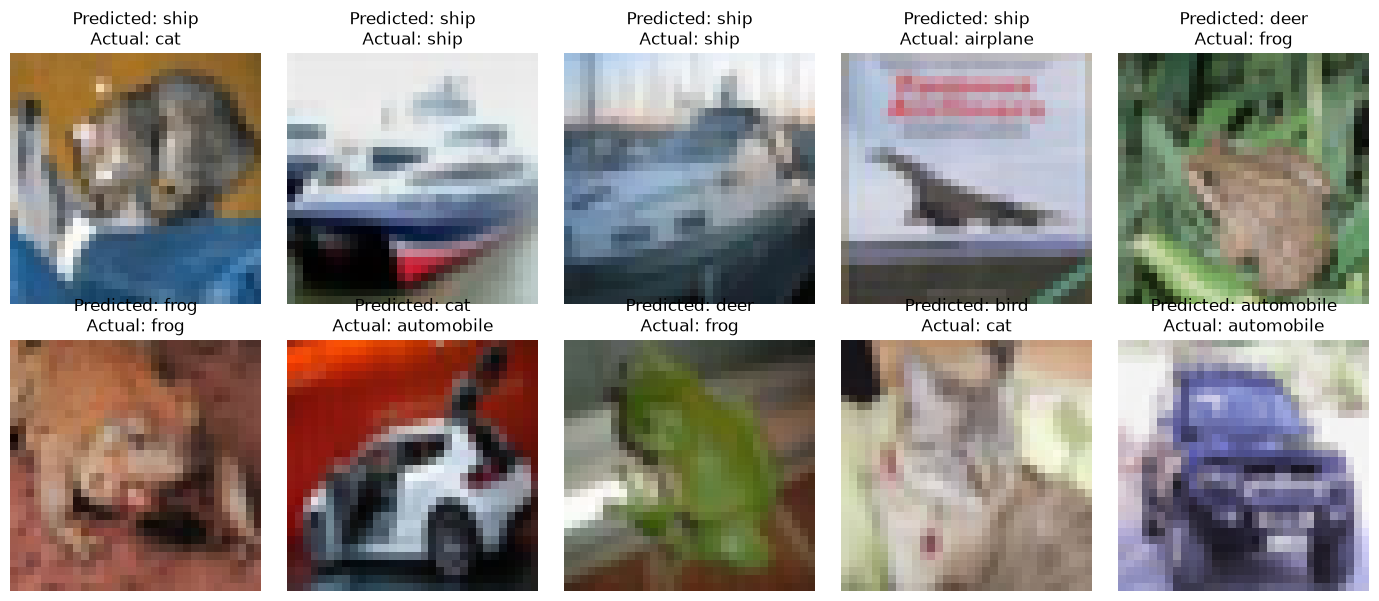

In [24]:
# Predict the first 10 test images
predictions = model.predict(X_test[:10], verbose=0)

# Select the class with the highest probability
predicted_labels = np.argmax(predictions, axis=1)

# Get the actual labels
actual_labels = y_test[:10]

# Display the images with their predictions
images_to_show = X_test[:10].reshape(-1, 32, 32, 3)

plt.figure(figsize=(14, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images_to_show[i])

    predicted_name = class_names[predicted_labels[i]]
    actual_name = class_names[actual_labels[i]]

    plt.title(
        f"Predicted: {predicted_name}\nActual: {actual_name}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
history_more = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 38s 26ms/step - accuracy: 0.4217 - loss: 1.6264 - val_accuracy: 0.4078 - val_loss: 1.6680
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - accuracy: 0.4242 - loss: 1.6229 - val_accuracy: 0.3988 - val_loss: 1.7064
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 78s 27ms/step - accuracy: 0.4242 - loss: 1.6166 - val_accuracy: 0.4196 - val_loss: 1.6519
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.4254 - loss: 1.6127 - val_accuracy: 0.4150 - val_loss: 1.6534
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 74s 25ms/step - accuracy: 0.4249 - loss: 1.6073 - val_accuracy: 0.4204 - val_loss: 1.6337
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.4274 - loss: 1.6045 - val_accuracy: 0.4266 - val_loss: 1.6466
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 34s 24ms/step - accuracy: 0.4295 - loss: 1.5996 - val_accuracy: 0.4168 - val_loss: 1.6451
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - accuracy: 0.4315 -

In [26]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4056 - loss: 1.6330
Test loss: 1.6329655647277832
Test accuracy: 40.56000113487244 %


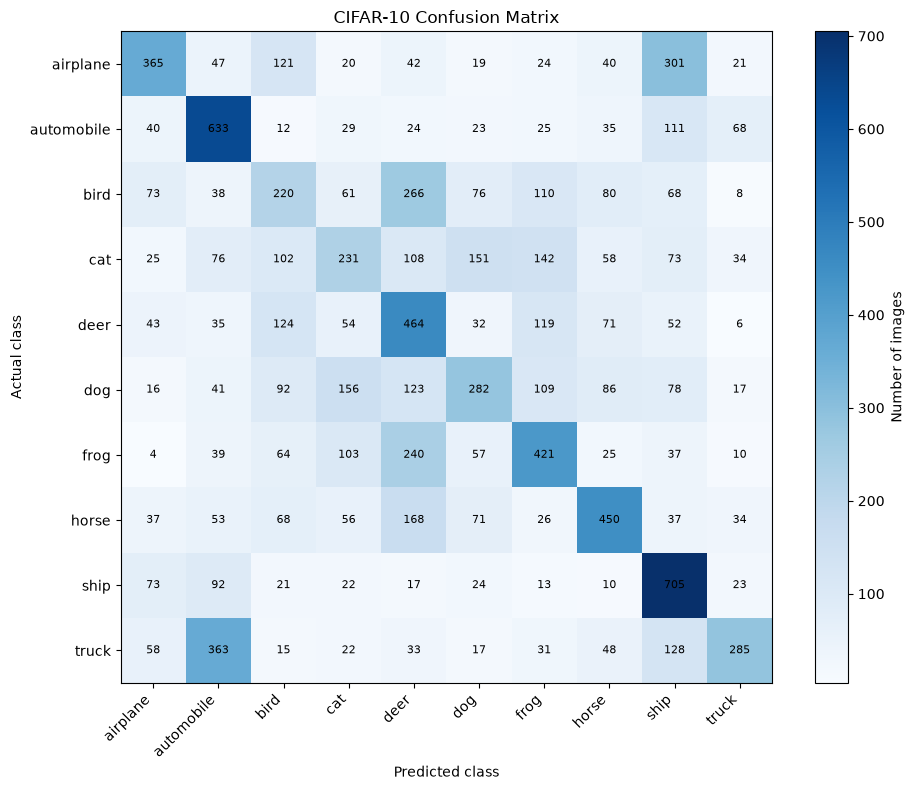

In [27]:
# Predict all test images
test_probabilities = model.predict(X_test, verbose=0)

# Select the class with the highest probability
predicted_classes = np.argmax(test_probabilities, axis=1)

# Create the confusion matrix
cm = tf.math.confusion_matrix(
    y_test,
    predicted_classes,
    num_classes=10
).numpy()

# Display the matrix
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Number of images")

plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("CIFAR-10 Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                 fontsize=8)

plt.tight_layout()
plt.show()

In [29]:
from pathlib import Path

# Create a folder to save our model
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save our trained model
model.save(model_dir / "cifar10_dense_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [30]:
loaded_model = tf.keras.models.load_model(
    model_dir / "cifar10_dense_model.keras"
)

print("Model loaded successfully!")
loaded_model.summary()

Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,183,904 (4.52 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 789,270 (3.01 MB)